# CSC 583 Natural Language Processing - Homework #4: N-gram Language Models

**Name:** Asad Khan
**Course / Section:** CSC 583 (Fall 2026)
**Assignment:** HW #4 - N-gram Language Models (Part I: N-gram Modeling and Perplexity; Part II: Text Generation)
**Collaborators:** None. GenAI disclosure: Claude (Anthropic) was used as a coding assistant.

---

## What this notebook does

**Part I (Steps 0 to 9)**

1. Reads the One Billion Word Benchmark subsets (`1b_benchmark.train.tokens`, `1b_benchmark.test.tokens`) from the course GitHub.
2. Builds the vocabulary from the **training set only**: tokens seen fewer than 3 times become `<unk>`, then `<STOP>` is added (26,602 types; `<START>` is not in the vocabulary).
3. Builds **unigram, bigram and trigram** models with `unigram()`, `bigram()` and `trigram()` (NLTK `FreqDist` / `ConditionalFreqDist` for the counts).
4. Implements `perplexity()` (no smoothing) and `perplexity_laplace()` (add-one smoothing) from scratch, using log probabilities.
5. Reports all 12 perplexity scores (3 models x 2 methods x train/test) and the evidence used in the write-up.

**Part II (Steps 10 to 17)**

6. Rebuilds the bigram and trigram models on the **whole dataset** (train + test) with a new vocabulary.
7. Generates sentences with my own decoding loop using greedy choice, random sampling and top-p (nucleus) sampling with several values of p.

## Step 0 - Setup

In [1]:
# CSC 583 - HW#4 N-gram Language Models (Part I) - Asad Khan
# On Google Colab, uncomment the next line to install NLTK
# !pip install nltk

import math
import collections
from urllib.request import urlopen

import nltk
import pandas as pd
import matplotlib.pyplot as plt

# Special symbols used throughout
START = '<START>'
STOP = '<STOP>'
UNK = '<unk>'

print("NLTK version:", nltk.__version__)

NLTK version: 3.10.3


## Step 1 - Read the data from GitHub

Each line is one sentence that is already whitespace-tokenized, so no preprocessing is needed:
I just split on whitespace and keep the tokens as they are (mixed case).

In [2]:
BASE_URL = "https://raw.githubusercontent.com/ntomuro/CSC583_2026Fall/main/HW4/ngram/"
TRAIN_URL = BASE_URL + "1b_benchmark.train.tokens"
TEST_URL = BASE_URL + "1b_benchmark.test.tokens"


def read_sentences_from_github(url):
    # Download the file once, then turn every non-empty line into a list of tokens
    text = urlopen(url).read().decode("utf-8")
    return [line.split() for line in text.splitlines() if line.strip()]


train_sents = read_sentences_from_github(TRAIN_URL)
test_sents = read_sentences_from_github(TEST_URL)

print(f"Training sentences: {len(train_sents):,}  tokens: {sum(map(len, train_sents)):,}")
print(f"Test sentences:     {len(test_sents):,}  tokens: {sum(map(len, test_sents)):,}")
print("\nFirst training sentence:\n", train_sents[0])

Training sentences: 61,530  tokens: 1,561,375
Test sentences:     12,105  tokens: 306,181

First training sentence:
 ['Having', 'a', 'little', 'flexibility', 'on', 'that', 'issue', 'would', 'go', 'a', 'long', 'way', 'to', 'putting', 'together', 'a', 'final', 'package', '.']


## Step 2 - Build the vocabulary (separate pre-step)

- Count tokens in the **training set only**.
- Tokens that occur **strictly fewer than 3 times** are lumped into `<unk>`.
- Add `<STOP>`. `<START>` is deliberately left out: the model never has to *predict* `<START>`,
  so it must not take part in normalizing the probabilities.

In [3]:
def build_vocab(sentences, min_count=3):
    counts = collections.Counter(tok for sent in sentences for tok in sent)
    vocab = {tok for tok, c in counts.items() if c >= min_count}
    vocab.add(UNK)
    vocab.add(STOP)
    return vocab, counts


vocab, train_counts = build_vocab(train_sents)
V = len(vocab)

rare_types = sum(1 for c in train_counts.values() if c < 3)
print(f"Raw training types:            {len(train_counts):,}")
print(f"Types seen < 3 times (-> <unk>): {rare_types:,}")
print(f"Vocabulary size |V|:            {V:,}")
assert V == 26602, "vocabulary size should be 26,602"
assert START not in vocab

Raw training types:            80,659
Types seen < 3 times (-> <unk>): 54,059
Vocabulary size |V|:            26,602


## Step 3 - Map tokens to the vocabulary and pad sentences

`prepare(sentence, n)` converts OOV tokens to `<unk>`, puts `n-1` `<START>` symbols in front
(none for the unigram, one for the bigram, two for the trigram) and `<STOP>` at the end.
The test set goes through exactly the same function, using the vocabulary built from training.

In [4]:
def to_vocab(sentence, vocabulary=None):
    # Replace out-of-vocabulary tokens with <unk> (Part I vocabulary unless another one is given)
    vocabulary = vocab if vocabulary is None else vocabulary
    return [tok if tok in vocabulary else UNK for tok in sentence]


def prepare(sentence, n, vocabulary=None):
    return [START] * (n - 1) + to_vocab(sentence, vocabulary) + [STOP]


example = train_sents[0]
for n in (1, 2, 3):
    print(f"n={n}:", prepare(example, n)[:8], "...", prepare(example, n)[-3:])

print("\nBigrams: ", list(nltk.ngrams(prepare(example, 2), 2))[:4], "...")
print("Trigrams:", list(nltk.ngrams(prepare(example, 3), 3))[:4], "...")

test_oov = sum(tok not in vocab for s in test_sents for tok in s)
test_tokens = sum(map(len, test_sents))
print(f"\nTest tokens mapped to <unk>: {test_oov:,} of {test_tokens:,} ({test_oov / test_tokens:.2%})")

n=1: ['Having', 'a', 'little', 'flexibility', 'on', 'that', 'issue', 'would'] ... ['package', '.', '<STOP>']
n=2: ['<START>', 'Having', 'a', 'little', 'flexibility', 'on', 'that', 'issue'] ... ['package', '.', '<STOP>']
n=3: ['<START>', '<START>', 'Having', 'a', 'little', 'flexibility', 'on', 'that'] ... ['package', '.', '<STOP>']

Bigrams:  [('<START>', 'Having'), ('Having', 'a'), ('a', 'little'), ('little', 'flexibility')] ...
Trigrams: [('<START>', '<START>', 'Having'), ('<START>', 'Having', 'a'), ('Having', 'a', 'little'), ('a', 'little', 'flexibility')] ...

Test tokens mapped to <unk>: 15,697 of 306,181 (5.13%)


## Step 4 - The N-gram models: `unigram()`, `bigram()`, `trigram()`

An N-gram model is just a probability table built from counts:

- **Unigram:** an NLTK `FreqDist` over every token (including `<STOP>`, excluding `<START>`).
  $P(w) = c(w) / N$, where $N$ is the number of training tokens.
- **Bigram:** a `ConditionalFreqDist` over the pairs from `nltk.ngrams(tokens, 2)`.
  `cfd[w1]` is the `FreqDist` of the words that followed `w1`, so `cfd[w1].freq(w2)` $= c(w_1 w_2) / c(w_1 \cdot)$.
- **Trigram:** the same, but the condition is the 2-tuple `(w1, w2)`, so `cfd[(w1, w2)].freq(w3)` $= c(w_1 w_2 w_3) / c(w_1 w_2 \cdot)$.

Using the count of the *context followed by anything* (`cfd[ctx].N()`) as the denominator matters for `<START>`:
`(<START>, <START>)` appears once per sentence, and `<STOP>` is never followed by anything.

Each function returns an `NgramLM` object that holds the counts and knows how to give
$P(w \mid \text{context})$ with and without Laplace smoothing:

$$P_{\text{MLE}}(w \mid h) = \frac{c(h, w)}{c(h)} \qquad\qquad P_{\text{Laplace}}(w \mid h) = \frac{c(h, w) + 1}{c(h) + |V|}$$

In [5]:
class NgramLM:
    # A unigram, bigram or trigram model backed by NLTK frequency counts

    def __init__(self, n, counts, vocab_size):
        self.n = n
        self.counts = counts          # FreqDist (n=1) or ConditionalFreqDist (n=2, 3)
        self.V = vocab_size

    def context(self, tokens, i):
        # The history used to predict tokens[i]
        if self.n == 1:
            return None
        if self.n == 2:
            return tokens[i - 1]
        return (tokens[i - 2], tokens[i - 1])

    def count(self, context, word):
        # Returns c(context, word) and c(context); .get() avoids creating empty entries
        if self.n == 1:
            return self.counts[word], self.counts.N()
        fd = self.counts.get(context)
        if fd is None:
            return 0, 0
        return fd[word], fd.N()

    def prob(self, context, word):
        # Maximum-likelihood probability via NLTK's freq(); 0 for an unseen context
        if self.n == 1:
            return self.counts.freq(word)
        fd = self.counts.get(context)
        return fd.freq(word) if fd is not None else 0.0

    def prob_laplace(self, context, word):
        # Add-one: every word in V gets one extra count, so the denominator grows by |V|
        c_hw, c_h = self.count(context, word)
        return (c_hw + 1) / (c_h + self.V)


# Each builder takes an optional vocabulary; Part I uses the training vocabulary,
# Part II passes the vocabulary built from train + test.

def unigram(sentences, vocabulary=None):
    # FreqDist of every token (OOV -> <unk>, plus <STOP>, no <START>)
    vocabulary = vocab if vocabulary is None else vocabulary
    fd = nltk.FreqDist(tok for sent in sentences for tok in prepare(sent, 1, vocabulary))
    return NgramLM(1, fd, len(vocabulary))


def bigram(sentences, vocabulary=None):
    # ConditionalFreqDist: condition = previous word, sample = next word
    vocabulary = vocab if vocabulary is None else vocabulary
    pairs = (bg for sent in sentences for bg in nltk.ngrams(prepare(sent, 2, vocabulary), 2))
    return NgramLM(2, nltk.ConditionalFreqDist(pairs), len(vocabulary))


def trigram(sentences, vocabulary=None):
    # ConditionalFreqDist: condition = (w1, w2) tuple, sample = w3
    vocabulary = vocab if vocabulary is None else vocabulary
    triples = (((w1, w2), w3) for sent in sentences
               for w1, w2, w3 in nltk.ngrams(prepare(sent, 3, vocabulary), 3))
    return NgramLM(3, nltk.ConditionalFreqDist(triples), len(vocabulary))


uni_lm = unigram(train_sents)
bi_lm = bigram(train_sents)
tri_lm = trigram(train_sents)
models = {"Unigram": uni_lm, "Bigram": bi_lm, "Trigram": tri_lm}

print(f"Unigram: {uni_lm.counts.B():,} types, {uni_lm.counts.N():,} tokens")
print(f"Bigram:  {len(bi_lm.counts.conditions()):,} contexts, {bi_lm.counts.N():,} bigram tokens, "
      f"{sum(fd.B() for fd in bi_lm.counts.values()):,} distinct bigrams")
print(f"Trigram: {len(tri_lm.counts.conditions()):,} contexts, {tri_lm.counts.N():,} trigram tokens, "
      f"{sum(fd.B() for fd in tri_lm.counts.values()):,} distinct trigrams")

Unigram: 26,602 types, 1,622,905 tokens
Bigram:  26,602 contexts, 1,622,905 bigram tokens, 510,391 distinct bigrams
Trigram: 510,364 contexts, 1,622,905 trigram tokens, 1,116,132 distinct trigrams


### Sanity checks

A language model must give a proper distribution over the vocabulary for every context.
Below, for a few contexts, the probabilities summed over all 26,602 vocabulary words should be 1.0
for both the unsmoothed and the Laplace versions.

In [6]:
vocab_list = sorted(vocab)
checks = [(uni_lm, None), (bi_lm, START), (bi_lm, "the"), (tri_lm, (START, START)), (tri_lm, ("of", "the"))]

rows = []
for lm, ctx in checks:
    rows.append({
        "model": f"{lm.n}-gram",
        "context": str(ctx),
        "sum P_MLE": round(sum(lm.prob(ctx, w) for w in vocab_list), 10),
        "sum P_Laplace": round(sum(lm.prob_laplace(ctx, w) for w in vocab_list), 10),
    })
display(pd.DataFrame(rows))

print("A few probabilities:")
print("  P(the)                   =", round(uni_lm.prob(None, "the"), 5))
print("  P(The | <START>)         =", round(bi_lm.prob(START, "The"), 5))
print("  P(States | United)       =", round(bi_lm.prob("United", "States"), 5))
print("  P(York | <START>, New)   =", round(tri_lm.prob((START, "New"), "York"), 5))

,model,context,sum P_MLE,sum P_Laplace
0,1-gram,None,1.0,1.0
1,2-gram,<START>,1.0,1.0
2,2-gram,the,1.0,1.0
3,3-gram,"('<START>', '<START>')",1.0,1.0
4,3-gram,"('of', 'the')",1.0,1.0


A few probabilities:
  P(the)                   = 0.04491
  P(The | <START>)         = 0.14486
  P(States | United)       = 0.64439
  P(York | <START>, New)   = 0.32468


## Step 5 - Perplexity

Perplexity of a token sequence $w_1 \dots w_M$ is computed with the log-space form from the assignment,
which never multiplies probabilities together, so it cannot underflow:

$$PP = \Big(\prod_{i=1}^{M} P(w_i \mid h_i)\Big)^{-\frac{1}{M}} = \exp\Big(-\frac{1}{M}\sum_{i=1}^{M} \ln P(w_i \mid h_i)\Big)$$

How I apply it to a whole file:

- Each line is its own sentence: n-grams never cross line boundaries, and each line ends in `<STOP>`.
- I sum $\ln P$ over **every predicted token of every sentence** (the real words plus `<STOP>`; `<START>` is
  never predicted, so it is not counted) and divide by the total number of predicted tokens $M$.
  This is the token-weighted average from the UW hints, so short sentences do not get extra weight.
- **No smoothing:** if any test token has $P = 0$ (an unseen n-gram, or an unseen trigram context),
  $\ln 0 = -\infty$ and the perplexity of the whole set is $\infty$. The function returns `math.inf`
  in that case and also reports how many zero-probability tokens there were.

Pseudo code:
```
log_sum = 0; M = 0; zeros = 0
for each sentence:
    tokens = [<START>]*(n-1) + vocab-mapped words + [<STOP>]
    for i from n-1 to len(tokens)-1:
        p = P(tokens[i] | previous n-1 tokens)
        M += 1
        if p == 0: zeros += 1   else: log_sum += ln(p)
perplexity = inf if zeros > 0 else exp(-log_sum / M)
```

In [7]:
def _perplexity(lm, sentences, prob_fn):
    # Shared loop; prob_fn(context, word) is either lm.prob or lm.prob_laplace
    log_sum, M, zeros = 0.0, 0, 0
    for sent in sentences:
        tokens = prepare(sent, lm.n)
        for i in range(lm.n - 1, len(tokens)):
            p = prob_fn(lm.context(tokens, i), tokens[i])
            M += 1
            if p == 0.0:
                zeros += 1
            else:
                log_sum += math.log(p)
    ppl = math.inf if zeros else math.exp(-log_sum / M)
    return ppl, {"tokens": M, "zero_prob_tokens": zeros, "log_sum": log_sum}


def perplexity(lm, sentences):
    # Unsmoothed (MLE) perplexity; returns (perplexity, details)
    return _perplexity(lm, sentences, lm.prob)


def perplexity_laplace(lm, sentences):
    # Perplexity with add-one (Laplace) smoothing; returns (perplexity, details)
    return _perplexity(lm, sentences, lm.prob_laplace)


# Tiny check against a hand calculation: the unigram on one short sentence
s = [["the", "cat"]]
p_manual = [uni_lm.prob(None, w) for w in to_vocab(s[0]) + [STOP]]
manual = math.exp(-sum(map(math.log, p_manual)) / len(p_manual))
print("hand-computed:", round(manual, 4), " perplexity():", round(perplexity(uni_lm, s)[0], 4))

hand-computed: 324.0839  perplexity(): 324.0839


## Step 6 - Results: all 12 perplexity scores

In [8]:
results = []
details = {}
for split_name, sents in [("Train", train_sents), ("Test", test_sents)]:
    for name, lm in models.items():
        for method, fn in [("Unsmoothed", perplexity), ("Laplace", perplexity_laplace)]:
            ppl, info = fn(lm, sents)
            details[(split_name, name, method)] = info
            results.append({"split": split_name, "model": name, "method": method,
                            "perplexity": ppl, "zero-prob tokens": info["zero_prob_tokens"],
                            "tokens scored": info["tokens"]})

results_df = pd.DataFrame(results)
summary = results_df.pivot_table(index="model", columns=["split", "method"], values="perplexity",
                                 aggfunc="first").reindex(["Unigram", "Bigram", "Trigram"])
summary = summary[[("Train", "Unsmoothed"), ("Train", "Laplace"), ("Test", "Unsmoothed"), ("Test", "Laplace")]]
display(summary.round(2))
display(results_df)

split        Train                Test         
method  Unsmoothed  Laplace Unsmoothed  Laplace
model                                          
Unigram     976.54   977.51      896.5   898.56
Bigram       77.07  1442.31        inf  1665.39
Trigram       7.87  6244.42        inf  9649.61

,split,model,method,perplexity,zero-prob tokens,tokens scored
0,Train,Unigram,Unsmoothed,976.543742,0,1622905
1,Train,Unigram,Laplace,977.507936,0,1622905
2,Train,Bigram,Unsmoothed,77.073466,0,1622905
3,Train,Bigram,Laplace,1442.308683,0,1622905
4,Train,Trigram,Unsmoothed,7.872968,0,1622905
5,Train,Trigram,Laplace,6244.424900,0,1622905
6,Test,Unigram,Unsmoothed,896.499491,0,318286
7,Test,Unigram,Laplace,898.556197,0,318286
8,Test,Bigram,Unsmoothed,inf,66335,318286
9,Test,Bigram,Laplace,1665.387326,0,318286


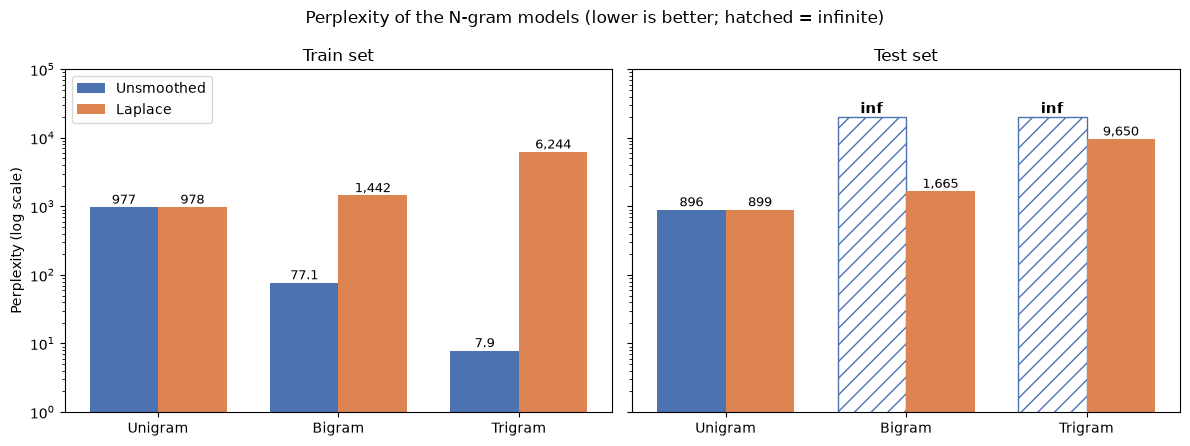

In [9]:
# Grouped bar chart on a log scale; infinite values are marked instead of drawn
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
colors = {"Unsmoothed": "#4C72B0", "Laplace": "#DD8452"}
names = ["Unigram", "Bigram", "Trigram"]
for ax, split_name in zip(axes, ["Train", "Test"]):
    for j, method in enumerate(["Unsmoothed", "Laplace"]):
        for k, name in enumerate(names):
            val = summary.loc[name, (split_name, method)]
            x = k + (j - 0.5) * 0.38
            if math.isinf(val):
                ax.bar(x, 2e4, width=0.38, color="white", edgecolor=colors[method], hatch="//")
                ax.text(x, 2.3e4, "inf", ha="center", fontsize=11, fontweight="bold")
            else:
                ax.bar(x, val, width=0.38, color=colors[method], label=method if k == 0 else None)
                ax.text(x, val * 1.12, f"{val:,.0f}" if val >= 100 else f"{val:.1f}", ha="center", fontsize=9)
    ax.set_xticks(range(3), names)
    ax.set_yscale("log")
    ax.set_ylim(1, 1e5)
    ax.set_title(f"{split_name} set")
axes[0].set_ylabel("Perplexity (log scale)")
axes[0].legend(loc="upper left")
fig.suptitle("Perplexity of the N-gram models (lower is better; hatched = infinite)")
plt.tight_layout()
plt.savefig("part1_perplexity.png", dpi=150)
plt.show()

## Step 7 - Why the unsmoothed test perplexities are infinite

The unigram never hits zero on the test set because every OOV word becomes `<unk>`, which is in the
vocabulary. The bigram and trigram models do: any test n-gram that never occurred in training gets
$P = 0$, and one zero makes the product zero (perplexity $\infty$). The table counts those tokens and
splits the trigram zeros into "context never seen" vs "context seen, but not followed by this word".

In [10]:
def zero_breakdown(lm, sentences):
    unseen_ctx, unseen_word, M = 0, 0, 0
    for sent in sentences:
        tokens = prepare(sent, lm.n)
        for i in range(lm.n - 1, len(tokens)):
            M += 1
            c_hw, c_h = lm.count(lm.context(tokens, i), tokens[i])
            if c_h == 0:
                unseen_ctx += 1
            elif c_hw == 0:
                unseen_word += 1
    return {"tokens": M, "context never seen": unseen_ctx, "context seen, word not": unseen_word,
            "zero-prob total": unseen_ctx + unseen_word,
            "% of test tokens with P=0": round(100 * (unseen_ctx + unseen_word) / M, 2)}


zero_df = pd.DataFrame({name: zero_breakdown(lm, test_sents) for name, lm in models.items()}).T
display(zero_df)

# First test sentence where the bigram model assigns zero probability
for sent in test_sents:
    toks = prepare(sent, 2)
    bad = [(toks[i - 1], toks[i]) for i in range(1, len(toks)) if bi_lm.prob(toks[i - 1], toks[i]) == 0]
    if bad:
        print("Test sentence:", " ".join(sent))
        print("Unseen bigrams:", bad)
        break

,tokens,context never seen,"context seen, word not",zero-prob total,% of test tokens with P=0
Unigram,318286.0,0.0,0.0,0.0,0.00
Bigram,318286.0,0.0,66335.0,66335.0,20.84
Trigram,318286.0,66334.0,122379.0,188713.0,59.29


Test sentence: BAGHDAD -- An Iraqi military commander on Monday compared new restrictions on the U.S. military to " house arrest , " saying American combat troops cannot patrol as freely as they did before pulling out of cities on June 30 .
Unseen bigrams: [('commander', 'on'), ('Monday', 'compared'), ('compared', 'new'), ('saying', 'American'), ('American', 'combat'), ('cannot', 'patrol'), ('patrol', 'as'), ('as', 'freely'), ('freely', 'as'), ('before', 'pulling')]


For context only (this is **not** a valid perplexity, and is not reported as one): if the zero-probability
tokens are simply skipped, the remaining tokens look very predictable. This shows that the higher-order
models are sharp on what they have seen, and the problem is purely the unseen n-grams.

In [11]:
rows = []
for name in ["Bigram", "Trigram"]:
    info = details[("Test", name, "Unsmoothed")]
    kept = info["tokens"] - info["zero_prob_tokens"]
    rows.append({"model": name, "tokens kept": kept, "share of test kept": f"{kept / info['tokens']:.1%}",
                 "PPL on kept tokens only": round(math.exp(-info["log_sum"] / kept), 2)})
display(pd.DataFrame(rows))

,model,tokens kept,share of test kept,PPL on kept tokens only
0,Bigram,251951,79.2%,68.28
1,Trigram,129573,40.7%,14.80


## Step 8 - The downside of Laplace smoothing (empirical evidence)

Laplace smoothing fixes the infinities, but it does so by giving **one pseudo-count to every one of the
26,602 vocabulary words in every context**. For a context seen only a few times, those 26,602 fake counts
swamp the real ones, so far too much probability mass moves to unseen events and the n-grams
we actually observed become much less likely. Four pieces of evidence follow.

### Evidence 1 - Perplexity on the *training* data gets much worse

On data the model has already seen, smoothing should cost almost nothing. Instead the bigram and trigram
training perplexities explode, while the unigram (one context with 1.6M tokens) is barely affected.

In [12]:
train_cmp = pd.DataFrame({
    "Unsmoothed": [summary.loc[m, ("Train", "Unsmoothed")] for m in names],
    "Laplace": [summary.loc[m, ("Train", "Laplace")] for m in names],
}, index=names)
train_cmp["Laplace / Unsmoothed"] = train_cmp["Laplace"] / train_cmp["Unsmoothed"]
display(train_cmp.round(2))

,Unsmoothed,Laplace,Laplace / Unsmoothed
Unigram,976.54,977.51,1.00
Bigram,77.07,1442.31,18.71
Trigram,7.87,6244.42,793.15


### Evidence 2 - Reconstituted counts: how much the seen n-grams are discounted

The Laplace probability can be turned back into an "effective count"
$c^*(h, w) = (c(h, w) + 1) \cdot \dfrac{c(h)}{c(h) + |V|}$ (J&M 3.6). Comparing $c^*$ with the real count
shows how much of each observed n-gram was given away.

In [13]:
def reconstituted_rows(lm, pairs):
    rows = []
    for ctx, w in pairs:
        c_hw, c_h = lm.count(ctx, w)
        p_mle = lm.prob(ctx, w)
        p_lap = lm.prob_laplace(ctx, w)
        c_star = (c_hw + 1) * c_h / (c_h + lm.V)
        rows.append({"n-gram": " ".join(ctx if isinstance(ctx, tuple) else [ctx]) + " " + w,
                     "c(h)": c_h, "c(h,w)": c_hw, "P_MLE": round(p_mle, 4), "P_Laplace": round(p_lap, 6),
                     "c* (effective count)": round(c_star, 2), "c* / c": round(c_star / c_hw, 4)})
    return rows


bigram_pairs = [("United", "States"), ("per", "cent"), ("New", "York"), ("of", "the"), ("I", "think")]
trigram_pairs = [(("the", "United"), "States"), (("New", "York"), "City"), (("one", "of"), "the"),
                 ((START, START), "The"), (("at", "least"), "one")]
display(pd.DataFrame(reconstituted_rows(bi_lm, bigram_pairs) + reconstituted_rows(tri_lm, trigram_pairs)))

,n-gram,c(h),"c(h,w)",P_MLE,P_Laplace,c* (effective count),c* / c
0,United States,793,511,0.6444,0.018690,14.82,0.0290
1,per cent,842,471,0.5594,0.017199,14.48,0.0307
2,New York,1025,579,0.5649,0.020994,21.52,0.0372
3,of the,34841,8342,0.2394,0.135784,4730.86,0.5671
4,I think,4110,251,0.0611,0.008205,33.72,0.1344
5,the United States,527,430,0.8159,0.015887,8.37,0.0195
6,New York City,579,56,0.0967,0.002097,1.21,0.0217
7,one of the,873,523,0.5991,0.019072,16.65,0.0318
8,<START> <START> The,61530,8913,0.1449,0.101144,6223.37,0.6982
9,at least one,456,30,0.0658,0.001146,0.52,0.0174


### Evidence 3 - Where the probability mass goes

For a context $h$ with $T(h)$ distinct observed continuations, the Laplace model gives the
$|V| - T(h)$ never-seen words a combined probability of $\dfrac{|V| - T(h)}{c(h) + |V|}$.
The histogram shows this for every context the test set actually uses (one value per test token).

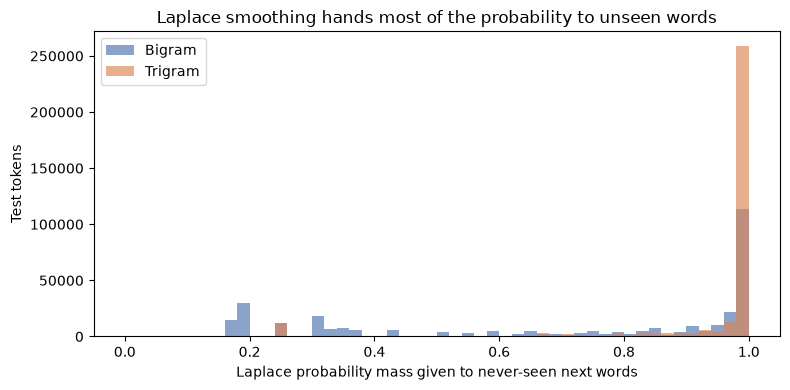

Unigram: 0.0000% of the mass goes to unseen words (every vocab word was seen)
Bigram: median 90.2%, mean 70.9%, share of test tokens whose context gives > 90% to unseen words: 50.3%
Trigram: median 99.9%, mean 95.2%, share of test tokens whose context gives > 90% to unseen words: 89.6%


In [14]:
def unseen_mass_per_token(lm, sentences):
    masses = []
    for sent in sentences:
        tokens = prepare(sent, lm.n)
        for i in range(lm.n - 1, len(tokens)):
            fd = lm.counts.get(lm.context(tokens, i))
            c_h, T = (fd.N(), fd.B()) if fd is not None else (0, 0)
            masses.append((lm.V - T) / (c_h + lm.V))
    return masses


uni_unseen = (V - uni_lm.counts.B()) / (uni_lm.counts.N() + V)
mass = {"Bigram": unseen_mass_per_token(bi_lm, test_sents),
        "Trigram": unseen_mass_per_token(tri_lm, test_sents)}

fig, ax = plt.subplots(figsize=(8, 4))
for name, color in [("Bigram", "#4C72B0"), ("Trigram", "#DD8452")]:
    ax.hist(mass[name], bins=50, range=(0, 1), alpha=0.65, color=color, label=name)
ax.set_xlabel("Laplace probability mass given to never-seen next words")
ax.set_ylabel("Test tokens")
ax.set_title("Laplace smoothing hands most of the probability to unseen words")
ax.legend()
plt.tight_layout()
plt.savefig("part1_laplace_unseen_mass.png", dpi=150)
plt.show()

print(f"Unigram: {uni_unseen:.4%} of the mass goes to unseen words (every vocab word was seen)")
for name, m in mass.items():
    s = pd.Series(m)
    print(f"{name}: median {s.median():.1%}, mean {s.mean():.1%}, "
          f"share of test tokens whose context gives > 90% to unseen words: {(s > 0.9).mean():.1%}")

### Evidence 4 - Seen test n-grams lose probability, and higher order becomes worse

Restricting to test tokens whose n-gram **was** seen in training, the plot compares the log probability
under the unsmoothed and Laplace models. Points below the diagonal were made less likely by smoothing.
The perplexity ranking on the test set also flips: with Laplace, more context makes the model *worse*
(unigram < bigram < trigram), the opposite of what an n-gram model with a good smoothing method shows.

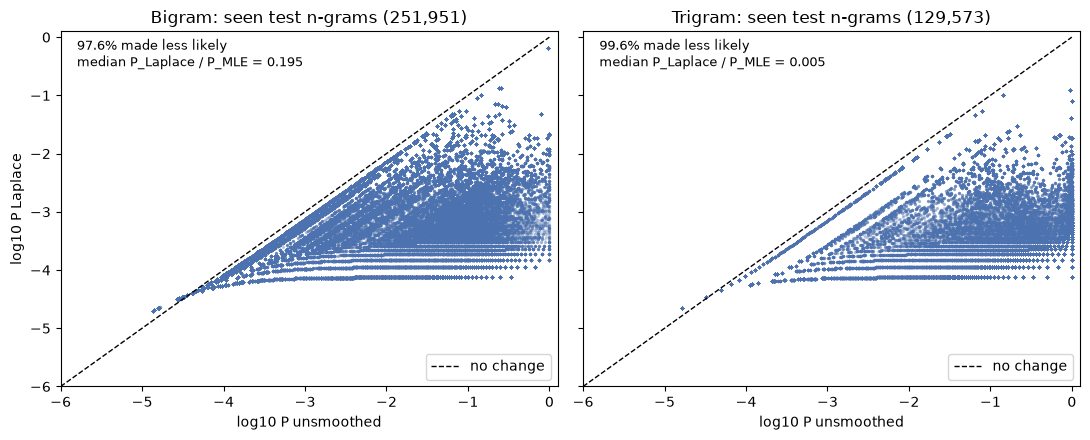

split,Test
method,Laplace
model,
Unigram,898.56
Bigram,1665.39
Trigram,9649.61


In [15]:
pts = {"Bigram": ([], []), "Trigram": ([], [])}
for name in pts:
    lm = models[name]
    for sent in test_sents:
        tokens = prepare(sent, lm.n)
        for i in range(lm.n - 1, len(tokens)):
            ctx = lm.context(tokens, i)
            p = lm.prob(ctx, tokens[i])
            if p > 0:
                pts[name][0].append(math.log10(p))
                pts[name][1].append(math.log10(lm.prob_laplace(ctx, tokens[i])))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (name, (x, y)) in zip(axes, pts.items()):
    ax.scatter(x, y, s=2, alpha=0.08, color="#4C72B0")
    ax.plot([-6, 0], [-6, 0], color="black", lw=1, ls="--", label="no change")
    ax.set_xlim(-6, 0.1)
    ax.set_ylim(-6, 0.1)
    ax.set_title(f"{name}: seen test n-grams ({len(x):,})")
    ax.set_xlabel("log10 P unsmoothed")
    lower = sum(b < a for a, b in zip(x, y)) / len(x)
    ratio = 10 ** pd.Series([b - a for a, b in zip(x, y)]).median()
    ax.text(-5.8, -0.5, f"{lower:.1%} made less likely\nmedian P_Laplace / P_MLE = {ratio:.3f}", fontsize=9)
    ax.legend(loc="lower right")
axes[0].set_ylabel("log10 P Laplace")
plt.tight_layout()
plt.savefig("part1_laplace_seen_ngrams.png", dpi=150)
plt.show()

display(summary[[("Test", "Laplace")]].round(2))

## Step 9 - Discussion of the results

| Model | Train, unsmoothed | Train, Laplace | Test, unsmoothed | Test, Laplace |
|---|---:|---:|---:|---:|
| Unigram | 976.54 | 977.51 | 896.50 | 898.56 |
| Bigram | 77.07 | 1,442.31 | inf | 1,665.39 |
| Trigram | 7.87 | 6,244.42 | inf | 9,649.61 |

**Training set, unsmoothed.** Perplexity falls sharply as the context grows (977 -> 77 -> 7.9). More history
makes the next word easier to predict, but the trigram number mostly shows memorization: there are 1.12M
distinct trigrams in 1.62M trigram tokens, so most trigram contexts were seen only once or twice and the
MLE model has simply learned those exact continuations.

**Test set, unsmoothed.** Only the unigram gives a finite number (896.5). It is a little *lower* than on the
training set because 5.1% of test tokens are OOV and become `<unk>`, a frequent and therefore cheap token
(it is 4.0% of training tokens). The bigram and trigram perplexities are infinite: 20.8% of test bigrams and
59.3% of test trigrams never appeared in training, and a single zero probability makes the whole product zero.
For 66,334 test tokens the trigram model has not even seen the two-word context. Skipping the zeros would give
68.3 and 14.8, but that is measured on a much easier subset of the data (79% and 41% of the tokens), so it
is not a real perplexity; it only shows the models are sharp on what they have seen.

**Laplace.** Add-one makes every test perplexity finite, but at a heavy price. The unigram is essentially
unchanged (one extra count per word is tiny next to 1.6M tokens), while the bigram goes to 1,442 / 1,665 and the
trigram to 6,244 / 9,650. Both are worse than the plain unigram, and the order is reversed: more context now
means a worse model. The reason is the 26,602 pseudo-counts per context. Most bigram and trigram contexts have
far fewer real observations than that, so smoothing moves most of the probability to unseen words (median
90% of the mass for bigram contexts and 99.9% for trigram contexts in the test set), and it discounts the seen
n-grams heavily: "United States" keeps only 2.9% of its count (c* = 14.8 of 511) and the median seen test
trigram gets 0.5% of its unsmoothed probability. Contexts that were never seen get a flat 1/|V| for every word.

**Takeaway.** Unsmoothed higher-order models cannot be evaluated on new text at all, and Laplace smoothing is
too blunt for a vocabulary this large. A useful n-gram model needs a gentler way to reserve mass for unseen
events: a much smaller add-k, or methods that fall back on lower-order estimates (backoff, interpolation,
Kneser-Ney) so a trigram with an unseen context can still use what the bigram and unigram know.

---

# Part II - Text Generation from N-gram Language Models

## Step 10 - Rebuild the models on the whole dataset

For generation the assignment asks for bigram and trigram models built from **train + test merged**,
with a **new vocabulary** from the merged data (tokens seen fewer than 3 times become `<unk>`, plus `<STOP>`).
The same `bigram()` / `trigram()` functions from Part I are reused; only the sentences and the vocabulary change.

In [16]:
all_sents = train_sents + test_sents
vocab_all, _ = build_vocab(all_sents)

bi_gen = bigram(all_sents, vocab_all)
tri_gen = trigram(all_sents, vocab_all)
gen_models = {"Bigram": bi_gen, "Trigram": tri_gen}

print(f"Merged sentences: {len(all_sents):,}  tokens: {sum(map(len, all_sents)):,}")
print(f"New vocabulary |V|: {len(vocab_all):,}  (Part I training vocabulary was {V:,})")
print(f"Bigram contexts:  {len(bi_gen.counts.conditions()):,}")
print(f"Trigram contexts: {len(tri_gen.counts.conditions()):,}")

Merged sentences: 73,635  tokens: 1,867,556
New vocabulary |V|: 29,479  (Part I training vocabulary was 26,602)
Bigram contexts:  29,479
Trigram contexts: 589,179


## Step 11 - The generation routine (my own implementation)

The idea follows NLTK book ch. 2 section 2.4 ("Generating Random Text with Bigrams"), extended to trigrams and
to three next-word selection strategies:

1. Start from the padded history: `[<START>]` for the bigram, `[<START>, <START>]` for the trigram.
2. Look up the context (last 1 or 2 words) in the `ConditionalFreqDist`; its `FreqDist` is the
   distribution over next words, sorted with `most_common()`.
3. Choose the next word with a strategy:
   - **Greedy:** always the most frequent next word.
   - **Random sampling:** draw a word with probability $c(h, w) / c(h)$.
   - **Top-p (nucleus) sampling:** keep the smallest set of most likely words whose probabilities add up
     to at least $p$, renormalise, and sample from that set only.
4. Append the word and repeat. Stop when `<STOP>` is chosen or 100 words have been generated.

The first chosen word X gives the seed n-gram (`<START>`, X) or (`<START>`, `<START>`, X), so the seed is picked
by the same strategy. Every context reached during generation was itself seen in the corpus, so the lookup never fails.

In [17]:
import random

MAX_WORDS = 100


def next_word_distribution(lm, context):
    # [(word, count), ...] for everything that followed this context, most frequent first
    fd = lm.counts.get(context)
    if fd is None:
        raise KeyError(f"context never seen: {context}")
    return fd.most_common()


def choose_greedy(dist, rng):
    return dist[0][0]


def choose_random(dist, rng):
    words, counts = zip(*dist)
    return rng.choices(words, weights=counts)[0]


def make_top_p(p):
    # Returns a chooser that samples only from the smallest high-probability set with mass >= p
    def choose_top_p(dist, rng):
        total = sum(c for _, c in dist)
        nucleus, mass = [], 0
        for w, c in dist:
            nucleus.append((w, c))
            mass += c
            if mass / total >= p:
                break
        words, counts = zip(*nucleus)
        return rng.choices(words, weights=counts)[0]
    return choose_top_p


def generate(lm, choose, rng, max_words=MAX_WORDS):
    # Returns (list of generated words, True if <STOP> was produced)
    history = [START] * (lm.n - 1)
    words = []
    while len(words) < max_words:
        context = history[-1] if lm.n == 2 else (history[-2], history[-1])
        w = choose(next_word_distribution(lm, context), rng)
        if w == STOP:
            return words, True
        words.append(w)
        history.append(w)
    return words, False


def show(words, stopped):
    return " ".join(words) + ("" if stopped else "  [hit the 100-word limit]")


# What the strategies see at the very first step of the bigram model
start_dist = next_word_distribution(bi_gen, START)
total = sum(c for _, c in start_dist)
print("Most likely first words after <START> (bigram):")
for w, c in start_dist[:8]:
    print(f"  {w:<10} {c / total:.3f}")


def nucleus_size(dist, p):
    # How many of the most likely words top-p keeps for this distribution
    total, mass = sum(c for _, c in dist), 0
    for i, (_, c) in enumerate(dist, 1):
        mass += c
        if mass / total >= p:
            return i


for p in (0.2, 0.5, 0.8, 0.95):
    print(f"top-p nucleus size at p={p}: {nucleus_size(start_dist, p):,} of {len(start_dist):,} possible first words")

Most likely first words after <START> (bigram):
  The        0.145
  <unk>      0.072
  "          0.065
  But        0.031
  He         0.029
  It         0.029
  In         0.028
  A          0.023
top-p nucleus size at p=0.2: 2 of 5,536 possible first words
top-p nucleus size at p=0.5: 15 of 5,536 possible first words
top-p nucleus size at p=0.8: 314 of 5,536 possible first words
top-p nucleus size at p=0.95: 2,491 of 5,536 possible first words


## Step 12 - Greedy choice

Greedy decoding is deterministic, so each model produces exactly one sentence.

In [18]:
greedy_out = {}
for name, lm in gen_models.items():
    greedy_out[name] = generate(lm, choose_greedy, random.Random(0))
    words, stopped = greedy_out[name]
    print(f"{name} greedy ({len(words)} words):\n  {show(words, stopped)}\n")

# Why greedy never stops: the most likely next word forms a cycle that never reaches <STOP>
print("Bigram argmax chain:")
for ctx in [START, "The", "<unk>", ",", "the"]:
    w, c = next_word_distribution(bi_gen, ctx)[0]
    print(f"  {ctx!r:>10} -> {w!r:<8} P = {c / bi_gen.counts[ctx].N():.3f}")
print("Trigram argmax chain:")
for ctx in [(START, START), (START, "The"), ("The", "<unk>"), ("<unk>", "<unk>"), ("<unk>", ","), (",", "<unk>")]:
    w, c = next_word_distribution(tri_gen, ctx)[0]
    print(f"  {str(ctx):>22} -> {w!r:<8} P = {c / tri_gen.counts[ctx].N():.3f}")

Bigram greedy (100 words):
  The <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the  [hit the 100-word limit]

Trigram greedy (100 words):
  The <unk> <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> ,  [hit the 100-word limit]

Bigram argmax chain:
   '<START>' -> 'The'    P = 0.145
       'The' -> '<unk>'  P = 

## Step 13 - Random sampling

Each next word is drawn in proportion to its count. A fixed seed makes the run reproducible.

In [19]:
N_SHOW = 8
random_samples = {}
for name, lm in gen_models.items():
    rng = random.Random(583)
    random_samples[name] = [generate(lm, choose_random, rng) for _ in range(N_SHOW)]
    print(f"===== {name}: random sampling =====")
    for i, (words, stopped) in enumerate(random_samples[name], 1):
        print(f"[{i}] {show(words, stopped)}")
    print()

===== Bigram: random sampling =====
[1] At the Reds lately developed by reading public comment about 73 ) -- Kimberley process of collapsed in the less regulation of <unk> Society & S & OVER , has gone to get inspectors because he would not talking once had made his decision was born in this week .
[2] According to knock at the decisions .
[3] It was about this week goes off a <unk> 's largest minority hiring someone to ensure that the manifestations , no legal damages .
[4] Obama 's interest Professor Nutt , because missiles , said they actually went on "
[5] The republican politicians should act was " as a plant passport and comic , which prescriptions people in financial sector workers as saying that the Tribeca apartment . -- and owned by 2018 or several of the lives " Mr Salmond yet been deployed smaller packages of state from humor .
[6] The handwritten notes on Wednesday , Hyde 's administrative expenses for Travel Channel .
[7] I use them .
[8] Another skier , but like the manu

## Step 14 - Top-p (nucleus) sampling with different p

Small p keeps only the few most likely words (close to greedy); p near 1 keeps almost everything (close to random sampling).

In [20]:
P_VALUES = [0.2, 0.5, 0.8, 0.95]
top_p_samples = {}
for name, lm in gen_models.items():
    for p in P_VALUES:
        rng = random.Random(583)
        top_p_samples[(name, p)] = [generate(lm, make_top_p(p), rng) for _ in range(N_SHOW)]
        print(f"===== {name}: top-p, p = {p} =====")
        for i, (words, stopped) in enumerate(top_p_samples[(name, p)], 1):
            print(f"[{i}] {show(words, stopped)}")
        print()

===== Bigram: top-p, p = 0.2 =====
[1] The <unk> <unk> <unk> <unk> , and a day .
[2] The new .
[3] The man who was <unk> <unk> , the second time , the way to be the <unk> , <unk> , "
[4] The US military , "
[5] The new , the same time , the company 's new <unk> , and <unk> <unk> , "
[6] The <unk> .
[7] The <unk> , the United States , "
[8] The <unk> .



===== Bigram: top-p, p = 0.5 =====
[1] " <unk> 's team of the economic data and three points , but you have been very , " and one of the opening round of the vote for a deal with the murder of <unk> <unk> <unk> said he was also was <unk> and a <unk> .
[2] <unk> , who has had been in <unk> , which was no more than the high speed of the time , <unk> 's own a group of the title of a chance of the season , " he did not be found at the way .
[3] <unk> <unk> and <unk> , in the number of <unk> , a <unk> ) -- the entire family and into the U.S. auto industry , who are not be enough .
[4] That 's parent , an <unk> of the <unk> and were up a majority of them in the <unk> and so long time , " for a bit of the boy .
[5] The court that the show that <unk> ( UPI ) , who have been made up to me , to save more than <unk> <unk> , including in 2008 , <unk> ) - £ 5,000 people in the top of it to a positive impression of three months of the <unk> with the <unk> was not only the crisis .
[6] But the proces

===== Bigram: top-p, p = 0.8 =====
[1] I think I 'd hoped to hear at about 10 November 's victory by a second week that the cold snap a series , if they were barred from their employees .
[2] 10 % in a young talent scouts .
[3] But he 's all the school , which was named for best .
[4] After the movie .
[5] But they were armed authorities have been seen as he can only about it 's <unk> houses that people and rape and do that he had 13 weeks .
[6] Speaking on a Shiite .
[7] " of the <unk> reports that was simply doesn 't give the hand <unk> .
[8] <unk> .



===== Bigram: top-p, p = 0.95 =====
[1] She said they say he was ousted Mr. risk to harvest , where apparently to make phone messages and terrorism in the group would increase of the firing the scheme and <unk> .
[2] He will take part of authoritarian or she 's efforts , a <unk> to be sent to lose weight figure out of HIV / 11 million euros .
[3] <unk> Germany that they are taking a party would <unk> in which are the trails .
[4] They grow to comment about the North launched after the Yankees felt they will host Rush Limbaugh in Europe 's <unk> 2009 , including restructuring process of how to thank what he described as well into question is free and called a shock .
[5] Life fell sharply at the embassy , Wood , especially in the center will never returned home on first report on the wake of 86 % of the swearing and financial sector , press individual policyholders in <unk> answer to hear about to insure assets , the availability of the rest on the three-time MVP received international 

## Step 15 - Comparing the strategies with numbers

To back up the impressions from reading the samples, I generate 300 sentences per model and strategy and measure:

- **avg words**: sentence length; **% hit limit**: share that never produced `<STOP>` within 100 words;
- **distinct-2**: unique bigrams / all bigrams across the 300 sentences (higher = more varied output);
- **% copied**: share of generated sentences that appear word for word in the corpus (memorisation);
- **% <unk>**: share of generated words that are `<unk>`.

In [21]:
corpus_sentences = {" ".join(to_vocab(s, vocab_all)) for s in all_sents}


def strategy_stats(lm, choose, n_samples=300, seed=7):
    rng = random.Random(seed)
    samples = [generate(lm, choose, rng) for _ in range(n_samples)]
    lengths = [len(w) for w, _ in samples]
    bigrams = [bg for w, _ in samples for bg in zip(w, w[1:])]
    n_words = sum(lengths)
    return {
        "avg words": round(sum(lengths) / n_samples, 1),
        "% hit limit": round(100 * sum(not s for _, s in samples) / n_samples, 1),
        "distinct-2": round(len(set(bigrams)) / max(len(bigrams), 1), 3),
        "% copied": round(100 * sum(" ".join(w) in corpus_sentences for w, s in samples if s) / n_samples, 1),
        "% <unk>": round(100 * sum(w.count(UNK) for w, _ in samples) / max(n_words, 1), 2),
    }


strategies = [("greedy", choose_greedy), ("random", choose_random)] + \
             [(f"top-p {p}", make_top_p(p)) for p in P_VALUES]
rows = []
for name, lm in gen_models.items():
    for label, choose in strategies:
        n = 1 if label == "greedy" else 300
        rows.append({"model": name, "strategy": label, **strategy_stats(lm, choose, n_samples=n)})
gen_stats = pd.DataFrame(rows)
display(gen_stats)

,model,strategy,avg words,% hit limit,distinct-2,% copied,% <unk>
0,Bigram,greedy,100.0,100.0,0.040,0.0,33.00
1,Bigram,random,24.2,1.0,0.844,0.3,3.64
2,Bigram,top-p 0.2,9.1,0.0,0.147,14.3,22.17
3,Bigram,top-p 0.5,17.4,0.0,0.504,3.0,7.71
4,Bigram,top-p 0.8,19.0,0.0,0.770,1.0,5.41
5,Bigram,top-p 0.95,22.0,1.7,0.837,0.3,3.96
6,Trigram,greedy,100.0,100.0,0.040,0.0,50.00
7,Trigram,random,25.5,0.7,0.849,1.0,4.14
8,Trigram,top-p 0.2,21.9,1.0,0.171,0.0,19.54
9,Trigram,top-p 0.5,22.4,0.7,0.622,0.0,6.71


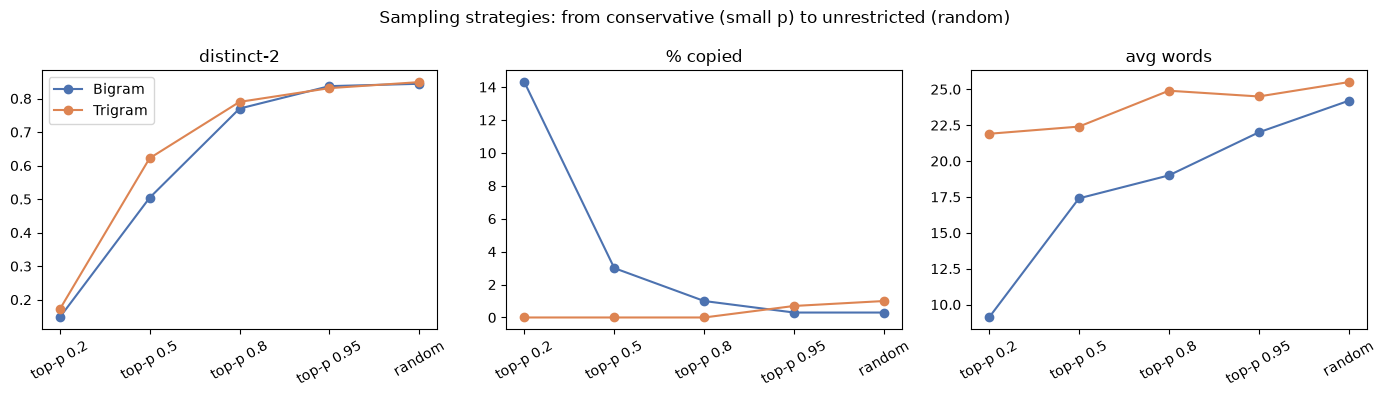

In [22]:
order = ["top-p 0.2", "top-p 0.5", "top-p 0.8", "top-p 0.95", "random"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["distinct-2", "% copied", "avg words"]):
    for name, color in [("Bigram", "#4C72B0"), ("Trigram", "#DD8452")]:
        sub = gen_stats[gen_stats.model == name].set_index("strategy").loc[order]
        ax.plot(order, sub[metric], marker="o", color=color, label=name)
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=30)
axes[0].legend()
fig.suptitle("Sampling strategies: from conservative (small p) to unrestricted (random)")
plt.tight_layout()
plt.savefig("part2_strategy_stats.png", dpi=150)
plt.show()

## Step 16 - Selected sentences for the write-up

The sentences below are picked from the samples printed in Steps 13 and 14 (same seeds, so they are reproducible).
Each one is checked against the corpus so that word-for-word copies of a training sentence are flagged.

In [23]:
selection = {
    "Bigram": {
        "Greedy": [greedy_out["Bigram"]],
        "Random sampling": [random_samples["Bigram"][i] for i in (2, 5, 7)],
        "Top-p (p = 0.8)": [top_p_samples[("Bigram", 0.8)][i] for i in (0, 2)],
        "Top-p (p = 0.95)": [top_p_samples[("Bigram", 0.95)][5]],
        "Top-p (p = 0.2)": [top_p_samples[("Bigram", 0.2)][6]],
    },
    "Trigram": {
        "Greedy": [greedy_out["Trigram"]],
        "Random sampling": [random_samples["Trigram"][i] for i in (0, 2, 6)],
        "Top-p (p = 0.2)": [top_p_samples[("Trigram", 0.2)][i] for i in (2, 5)],
        "Top-p (p = 0.5)": [top_p_samples[("Trigram", 0.5)][5]],
        "Top-p (p = 0.95)": [top_p_samples[("Trigram", 0.95)][i] for i in (1, 6)],
    },
}
for model, groups in selection.items():
    print(f"========== {model} ==========")
    for strategy, items in groups.items():
        print(f"-- {strategy}")
        for words, stopped in items:
            text = show(words[:30], True) + (" ..." if len(words) > 30 else "") if not stopped else show(words, stopped)
            flag = "  (copied from corpus)" if stopped and " ".join(words) in corpus_sentences else ""
            print(f"   {text}{flag}")
    print()

========== Bigram ==========
-- Greedy
   The <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , the <unk> , ...
-- Random sampling
   It was about this week goes off a <unk> 's largest minority hiring someone to ensure that the manifestations , no legal damages .
   The handwritten notes on Wednesday , Hyde 's administrative expenses for Travel Channel .
   Another skier , but like the manufacturers to disclosures have registered to stay .
-- Top-p (p = 0.8)
   I think I 'd hoped to hear at about 10 November 's victory by a second week that the cold snap a series , if they were barred from their employees .
   But he 's all the school , which was named for best .
-- Top-p (p = 0.95)
   He said today include Montana series .
-- Top-p (p = 0.2)
   The <unk> , the United States , "

========== Trigram ==========
-- Greedy
   The <unk> <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> 

## Step 17 - Discussion of Part II

**How generation walks the model.** Generation is a walk through the `ConditionalFreqDist`: the current context
(one word for the bigram, two for the trigram) selects a row, the strategy picks one word from that row, and the
window slides forward by one word. The walk ends at `<STOP>` or after 100 words.

**Greedy choice** is the worst strategy here. Both models fall into a loop within a few words and hit the 100-word limit.
The argmax chain shows why: for the bigram, `the -> <unk> -> , -> the` is a cycle of most-likely words that never
reaches `<STOP>`; the trigram cycles between `<unk> ,` and `, <unk>`. `<unk>` is a real, very frequent token in the
model, so the most probable path is full of it. Taking the single best word at every step does not give the most
probable sentence, and it gives no variety at all (distinct-2 = 0.04).

**Random sampling** gives varied text (distinct-2 about 0.85) with a natural sentence length (about 24 words, close
to the corpus average of 25.4). Local word pairs or triples are grammatical, but the sentence drifts between topics
because the model only remembers one or two words. The trigram output is noticeably more fluent within phrases
("In an election office in Kathmandu on Saturday night .") than the bigram output.

**Top-p sampling** moves smoothly between the two. At the first step there are 5,536 possible words, and the nucleus
keeps 2 of them at p = 0.2, 15 at p = 0.5, 314 at p = 0.8 and 2,491 at p = 0.95. Small p behaves like a noisy greedy
search: short, generic, repetitive sentences full of `<unk>` (about 20% of words) and low diversity (distinct-2 0.15 to 0.17).
p = 0.8 to 0.95 removes only the long tail of very unlikely words and gives the best balance: nearly as varied
as random sampling, with slightly fewer odd word choices.

**Memorisation.** Most trigram contexts were seen only once or twice, so the trigram often has a single
continuation and reproduces long stretches of real sentences ("The government has been accused of failing to spot
that Baby Peter was suffering from ..."). Whole sentences are rarely copied word for word (0 to 1% for the trigram);
the bigram copies more at p = 0.2 (14%), but those are tiny generic sentences such as "The <unk> .".